**Вставляем табличку с местами по критериям**


In [2]:
from google.colab import files
uploaded = files.upload()

ModuleNotFoundError: No module named 'google.colab'

**Это изначальная версия кода, где все прописывается сразув коде**


In [5]:
#изначальный, упрощенный вариант, без использования таблички
import pandas as pd
# изначально
data = [
    {
        "name": "Городской сквер",
        "access": 2,
        "free_stay": 2,
        "social_use": 2,
        "restrictions": 2,
    },
    {
        "name": "Зона ожидания банка",
        "access": 1,
        "free_stay": 0,
        "social_use": 1,
        "restrictions": 0,
    },
    {
        "name": "Закрытый двор ЖК",
        "access": 0,
        "free_stay": 2,
        "social_use": 2,
        "restrictions": 0,
    },
]
# Создадим пустую табличку.
df = pd.DataFrame(data)

# Нормируем показатели до шкалы 0–100.
df["accessibility"] = (
    (df["access"] + df["free_stay"]) / 4 * 100
)

df["third_place_score"] = (
    (df["social_use"] + df["free_stay"]) / 4 * 100
)

# Предварительная классификация
def classify(row):
#Открытым местом будем считать то, где индекс публичности не ниже 70, преимущественноа закрытым - не выше 25, остальное - условно публичным
    if (
        row["accessibility"] >= 70
        and row["third_place_score"] >= 70
    ):
        return "Открытое третье место"

    if row["accessibility"] <= 25:
        return "Преимущественно закрытое"

    return "Условно публичное"

df["classification"] = df.apply(classify, axis=1)

print(
    df[
        [
            "name",
            "accessibility",
            "third_place_score",
            "classification",
        ]
    ].to_string(index=False)
)

               name  accessibility  third_place_score           classification
    Городской сквер          100.0              100.0    Открытое третье место
Зона ожидания банка           25.0               25.0 Преимущественно закрытое
   Закрытый двор ЖК           50.0              100.0        Условно публичное


А э

In [13]:
import pandas as pd

# Загружаем таблицу
file_path = r"C:\Users\PC\Downloads\classification_cowork_final.xlsx"

df = pd.read_excel(file_path, sheet_name="Лист1")

# Приводим названия полей к тем, что используются в коде
df = df.rename(columns={
    "open_access": "access",
    "time_limits": "restrictions",
})

# Нормируем показатели до шкалы 0–100
df["accessibility"] = (
    (df["access"] + df["free_stay"]) / 4 * 100
)

df["third_place_score"] = (
    (df["social_use"] + df["free_stay"]) / 4 * 100
)

# Предварительная классификация
def classify(row):
    # Открытое место: индексы не ниже 70
    # Закрытое место: доступность не выше 25
    # Остальные объекты считаются условно публичными

    if (
        row["accessibility"] >= 70
        and row["third_place_score"] >= 70
    ):
        return "Открытое третье место"

    if row["accessibility"] <= 25:
        return "Преимущественно закрытое"

    return "Условно публичное"


df["classification"] = df.apply(classify, axis=1)

# Выводим результаты классификации
print(
    df[
        [
            "ID",
            "name",
            "type",
            "accessibility",
            "third_place_score",
            "classification",
        ]
    ].to_string(index=False)
)

# Сводка по типам объектов
print("\nСредние значения по типам:")

print(
    df.groupby("type")[
        ["accessibility", "third_place_score"]
    ]
    .mean()
    .round(1)
    .to_string()
)

# Сохраняем результат в Excel
df.to_excel(
    r"C:\Users\PC\Downloads\classification_result.xlsx",
    index=False
)

print("\nРезультаты сохранены в classification_result.xlsx")

    ID                                                                                    name       type  accessibility  third_place_score           classification
SBR-01                                                        Аудитория Сбера / коворкинг R205  Коворкинг           75.0              100.0    Открытое третье место
SBR-02                                               «Гига Клуб» / флагманский коворкинг Сбера  Коворкинг           75.0              100.0    Открытое третье место
SBR-03                                                 Студенческий коворкинг / хаб-зона Сбера  Коворкинг           75.0              100.0    Открытое третье место
SBR-04                                                 Студенческий коворкинг / хаб-зона Сбера  Коворкинг           75.0              100.0    Открытое третье место
SBR-05 Коворкинг Сбера в новом корпусе цифровых и информационных технологий им. А.С. Вишнякова  Коворкинг           75.0              100.0    Открытое третье место
SBR-06    

##Далее делаем график отображающий средние значения индекса публичности для разных типов объектов

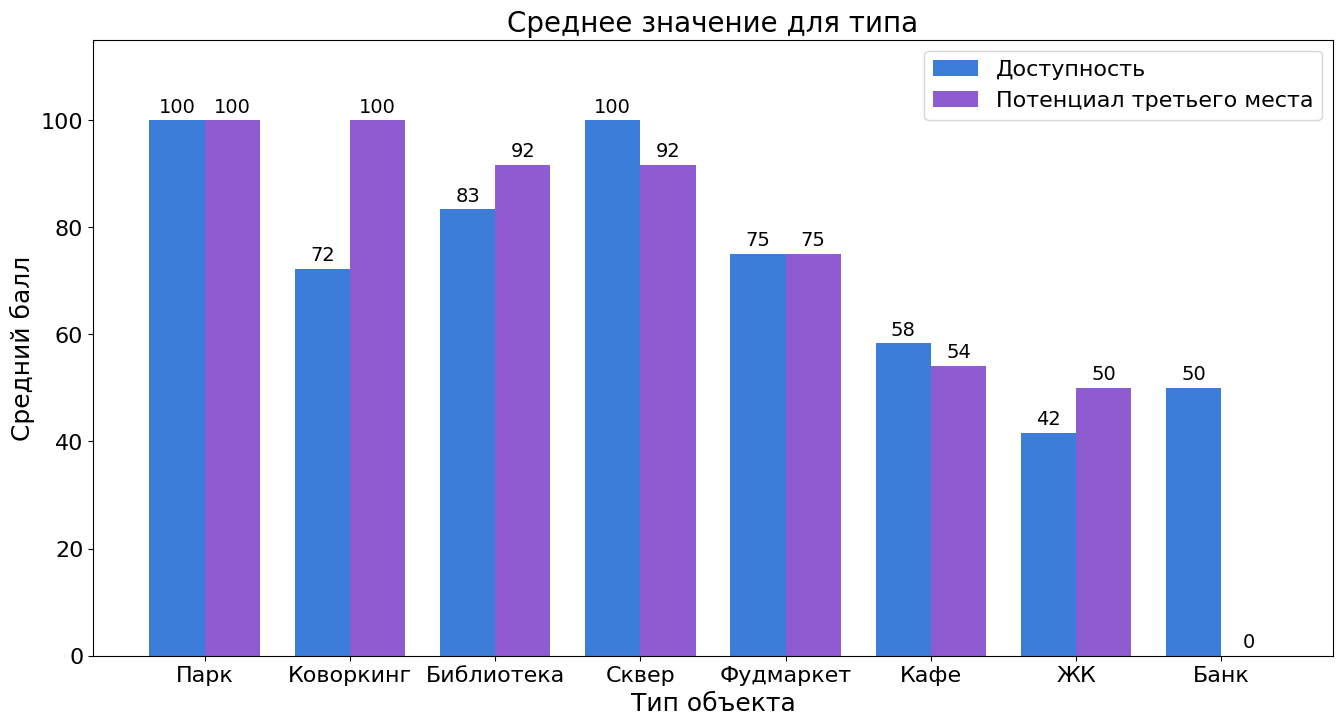

In [ ]:
# Построим график.
import numpy as np
import matplotlib.pyplot as plt
means = (df.groupby('type')[['accessibility', 'third_place_score']]
           .mean()
           .sort_values('third_place_score', ascending=False))

x = np.arange(len(means))
w = 0.38
plt.figure(figsize=(16,8))
b1 = plt.bar(x - w/2, means['accessibility'], w, label='Доступность', color='#3B7DD8')
b2 = plt.bar(x + w/2, means['third_place_score'], w, label='Потенциал третьего места', color='#8E5BD0')
plt.bar_label(b1, fmt='%.0f', fontsize=14, padding=3)
plt.bar_label(b2, fmt='%.0f', fontsize=14, padding=3)

plt.xticks(x, means.index)
plt.ylim(0, 115)
plt.xlabel('Тип объекта', fontsize=18)
plt.ylabel('Средний балл', fontsize=18)
plt.title('Среднее значение для типа', fontsize=20)
plt.legend(fontsize=16)
plt.gca().tick_params(labelsize=16)
plt.show()
# Парки имеют 100-процентный потенциал стать открытым местом, который использован полностью.
# Коворкинги также обладают 100-процентным потенциалом, однако средний бал составляет лишь 72.
# Библиотеки потенциально могут набирать 92 балла, но получили 83.
# Скверы получили 100 баллов, обогнав потенциал в 92 балла.
# Фудмаркеты использовали весь потенциал, равный потенциальным 75 баллам.
# Кафе обладают 54 баллами потенциалами, а набрали 58.
# ЖК обладают 50 баллами потенциала, но получили всего 42.
# Банки, несмотря на неочевидность имеет 50 баллов доступности.